# Chapter 4 — 주요 공격 유형 정밀 분석 (실습)

## 실습 목표
1. CICIDS2017 구조를 모사한 합성 데이터를 생성하고 라벨 분포를 본다.
2. DDoS·PortScan·BENIGN 라벨별 주요 feature 분포 차이를 시각화한다.
3. 본문의 '스캔 의심' 규칙을 코드로 구현하고 실제 라벨과 매칭률을 평가한다.
4. 결과를 표·히트맵으로 정리한다.

## 데이터셋
본 실습은 CICIDS2017 컬럼 구조를 모사한 **교육용 합성 데이터**를 생성한다(재현성·오프라인 실행).
실제 CICIDS2017 데이터셋은 UNB 에서 받아 교체할 수 있다: <https://www.unb.ca/cic/datasets/ids-2017.html>

---
## Step 0. 환경 설정

본 실습에서는 CICIDS2017 구조를 모사한 교육용 합성 데이터를 생성한다 (실제 데이터셋은 UNB 에서 받아 교체 가능).

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib

In [3]:
# 교육용 합성 데이터셋 (CICIDS2017 컬럼 구조를 모사)
# - 외부 다운로드 없음. 시드 고정으로 결과 재현 가능
# - Colab / 로컬(Windows·macOS·Linux) 어디서나 동일하게 동작
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path.cwd() / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
rng = np.random.default_rng(42)
n_benign, n_ddos, n_scan = 16000, 2300, 1200

def make_rows(n, label, flow_duration_range, pkts_range, syn_ratio_range, dst_port_choices):
    return pd.DataFrame({
        'Source IP': rng.choice([f'10.0.0.{i}' for i in range(1, 50)], size=n),
        'Destination Port': rng.choice(dst_port_choices, size=n),
        'Flow Duration': rng.uniform(*flow_duration_range, size=n),
        'Total Fwd Packets': rng.integers(*pkts_range, size=n),
        'SYN Flag Count': rng.uniform(*syn_ratio_range, size=n),
        'Label': label,
    })

df = pd.concat([
    make_rows(n_benign, 'BENIGN', (1000, 1_000_000), (5, 100), (0, 0.05), [80, 443, 53, 22]),
    make_rows(n_ddos,   'DDoS',   (10, 5000),         (500, 5000), (0.4, 0.7), [80, 443]),
    make_rows(n_scan,   'PortScan', (1, 200),         (1, 5),     (0.85, 1.0), list(range(1, 1024))),
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)

df.head()

,Source IP,Destination Port,Flow Duration,Total Fwd Packets,SYN Flag Count,Label
0,10.0.0.35,80,48068.615060,77,0.018195,BENIGN
1,10.0.0.28,53,961721.752453,30,0.030678,BENIGN
2,10.0.0.10,443,446554.504113,10,0.017566,BENIGN
3,10.0.0.24,998,15.809071,4,0.917880,PortScan
4,10.0.0.9,80,4960.320817,876,0.611898,DDoS


---
## Step 1. 라벨 분포 확인

In [5]:
label_pct = (df['Label'].value_counts(normalize=True) * 100).round(2)
print(label_pct)
print(f"\n총 {len(df):,} 행, 라벨 {df['Label'].nunique()}종")

Label
BENIGN      82.05
DDoS        11.79
PortScan     6.15
Name: proportion, dtype: float64

총 19,500 행, 라벨 3종


관찰: BENIGN 이 80% 이상으로 극심한 클래스 불균형. ch09 에서 이 문제를 다룬다.

---
## Step 2. 라벨별 Feature 분포 비교

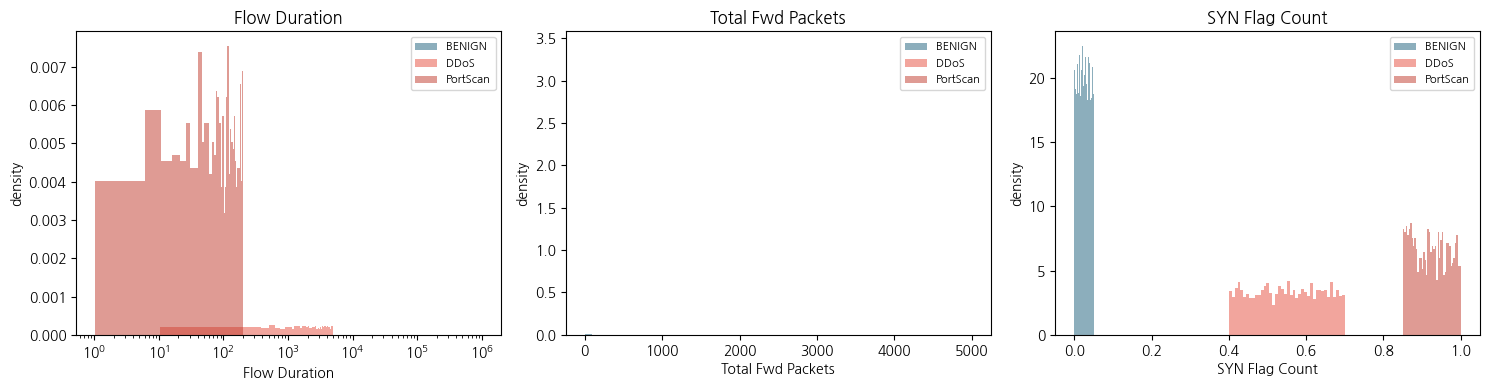

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ['Flow Duration', 'Total Fwd Packets', 'SYN Flag Count']
colors = {'BENIGN': '#1a5f7a', 'DDoS': '#e74c3c', 'PortScan': '#c0392b'}

for ax, feat in zip(axes, features):
    for label, color in colors.items():
        subset = df[df['Label'] == label][feat]
        ax.hist(subset, bins=40, alpha=0.5, label=label, color=color, density=True)
    ax.set_title(feat)
    ax.set_xlabel(feat)
    ax.set_ylabel('density')
    if feat == 'Flow Duration':
        ax.set_xscale('log')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

관찰:
- **Flow Duration**: BENIGN 은 넓게 분포, PortScan 은 매우 짧은 쪽에 집중 (한 번 SYN 후 종료).
- **Total Fwd Packets**: DDoS 는 큰 값, PortScan 은 작은 값.
- **SYN Flag Count**: PortScan 은 거의 1에 수렴 (SYN-only).

---
## Step 3. 본문의 '스캔 의심' 규칙 구현

In [7]:
# 규칙: SYN Flag Count > 0.85 그리고 Total Fwd Packets <= 5 그리고 Flow Duration < 500
rule_mask = (df['SYN Flag Count'] > 0.85) & (df['Total Fwd Packets'] <= 5) & (df['Flow Duration'] < 500)
df['rule_pred'] = np.where(rule_mask, 'PortScan', 'BENIGN')

# 실제 라벨이 PortScan 인지 여부로 평가
y_true = (df['Label'] == 'PortScan').astype(int)
y_pred = (df['rule_pred'] == 'PortScan').astype(int)

tp = int(((y_true == 1) & (y_pred == 1)).sum())
fp = int(((y_true == 0) & (y_pred == 1)).sum())
fn = int(((y_true == 1) & (y_pred == 0)).sum())
tn = int(((y_true == 0) & (y_pred == 0)).sum())

precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
print(f'TP={tp}, FP={fp}, FN={fn}, TN={tn}')
print(f'Precision={precision:.3f}, Recall={recall:.3f}')

TP=1200, FP=0, FN=0, TN=18300
Precision=1.000, Recall=1.000


> **공격자 시점**: 룰의 임계값만 알면 우회는 쉽다 — 스캔 속도를 늦추거나 패킷 길이를 조작하면 룰을 빠져나간다.
> 이 한계가 ch11 의 비지도 이상 탐지, ch14 의 지도학습 모델로 이어지는 동기다.

---
## Step 4. 룰 vs 라벨 혼동 행렬을 히트맵으로

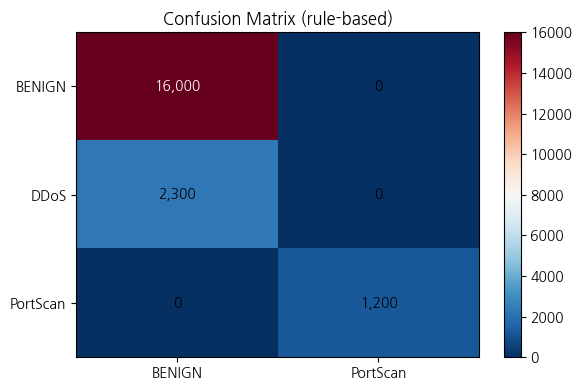

rule_pred,BENIGN,PortScan
actual,,
BENIGN,16000,0
DDoS,2300,0
PortScan,0,1200


In [8]:
cm = pd.crosstab(df['Label'], df['rule_pred'], rownames=['actual'], colnames=['rule_pred'])
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(cm.values, cmap='RdBu_r', aspect='auto')
ax.set_xticks(range(len(cm.columns))); ax.set_xticklabels(cm.columns)
ax.set_yticks(range(len(cm.index))); ax.set_yticklabels(cm.index)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f'{cm.values[i,j]:,}', ha='center', va='center', color='white' if cm.values[i,j] > cm.values.max()/2 else 'black')
ax.set_title('Confusion Matrix (rule-based)')
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
cm

---
## 챌린지

1. DDoS 도 룰로 잡아 보자. 어떤 feature 조합이 유효할까?
2. DDoS 에 대한 precision/recall 을 측정해 보라.

In [9]:
# DDoS 탐지 룰: 대량 순방향 패킷 + 높은 SYN 비율
df['ddos_flag'] = (df['Total Fwd Packets'] > 500) & (df['SYN Flag Count'] > 0.3)
hits = df[df['ddos_flag']]
print(f'룰 탐지 건수: {len(hits)}')
print(hits['Label'].value_counts())

# 간이 정밀도/재현율
tp = ((df['ddos_flag']) & (df['Label'] == 'DDoS')).sum()
fp = ((df['ddos_flag']) & (df['Label'] != 'DDoS')).sum()
fn = ((~df['ddos_flag']) & (df['Label'] == 'DDoS')).sum()
print(f'정밀도={tp/(tp+fp):.3f}  재현율={tp/(tp+fn):.3f}')

룰 탐지 건수: 2299
Label
DDoS    2299
Name: count, dtype: int64
정밀도=1.000  재현율=1.000


---
## 정리

- 룰 기반 탐지는 단순하고 빠르지만 우회되기 쉽다.
- 라벨별 feature 분포 차이가 시각화되면 직관적으로 어떤 feature 가 유효한지 보인다.
- 다음 챕터에서는 실제 PCAP 의 패킷 단위 분석으로 SYN Flood, ARP Spoof, DNS Poison 을 다룬다.